q1 at flux=0: w1 = 5.006791 GHz, alpha1 = -221.098 MHz
q2 fixed    : w2 = 4.523298 GHz, alpha2 = -223.837 MHz
g           = 10.000 MHz
phi_cphase   = -0.141500



 /usr/local/lib/python3.13/dist-packages/qutip/core/coefficient.py: 199

Chosen half-waveform:
phi          = -0.138500
t_hold_half  = 22.000 ns
P20_end      = 0.568688
P11_end      = 0.431130

first coarse t_idle scan
  t_idle=1.00 ns: P11=0.1333, phiCZ=85.57 deg (err 94.43), exchange=0.0018%
  t_idle=2.00 ns: P11=0.8406, phiCZ=155.08 deg (err 24.92), exchange=0.2659%
  t_idle=3.00 ns: P11=0.8453, phiCZ=148.85 deg (err 31.15), exchange=0.0002%
  t_idle=4.00 ns: P11=0.1334, phiCZ=79.02 deg (err 100.98), exchange=0.2644%
  t_idle=5.00 ns: P11=0.2506, phiCZ=103.48 deg (err 76.52), exchange=0.0044%
  t_idle=6.00 ns: P11=0.9425, phiCZ=166.13 deg (err 13.87), exchange=0.2575%
  t_idle=7.00 ns: P11=0.7068, phiCZ=137.50 deg (err 42.50), exchange=0.0138%
  t_idle=8.00 ns: P11=0.0552, phiCZ=49.54 deg (err 130.46), exchange=0.2456%
  t_idle=9.00 ns: P11=0.4025, phiCZ=118.00 deg (err 62.00), exchange=0.0281%
  t_idle=10.00 ns: P11=0.9945, phiCZ=177.04 deg (err 2.96), exchange=0.2291%
  t_idle=11.00 ns: P11=0.5459, phiCZ=125.62 deg (err 54.38), exchange=0.0467%
  t_idl

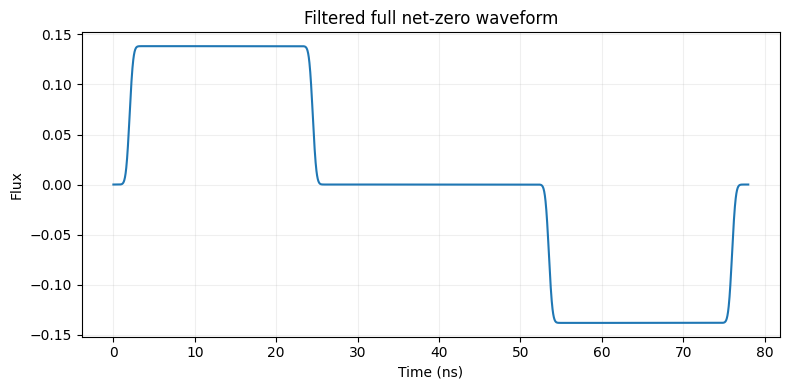

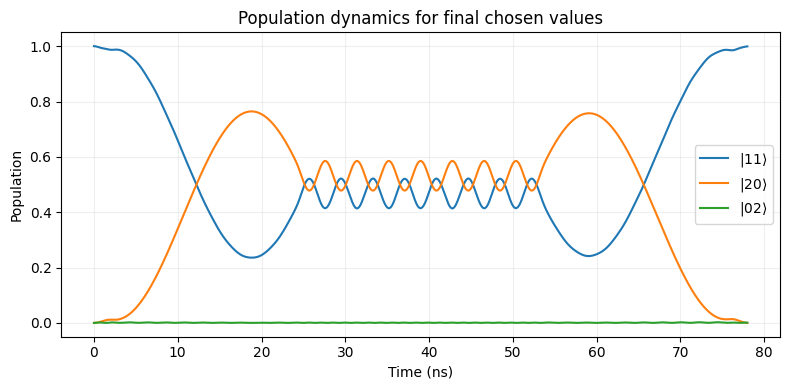

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
import scqubits as scq

from scipy.linalg import eigh
from scipy.interpolate import interp1d
from scipy.optimize import brentq, minimize_scalar

#piecewise constant (rectangular) waveform in discrete time steps
#hardware arbitrary waveform generator (AWG) smooths with gaussian kernel

#parameters

q1_ejmax = 17.0
q1_ec = 0.2
q1_d = 0.0

q2_ej = 14.0
q2_ec = 0.2

g_val = 0.01 #10 MHz

#truncations
nq1_scq = 15
nq2_scq = 12
n = 4

#flux lookup
flux_min = -0.40
flux_max = 0.40
nflux = 1601

# waveform sampling
dt_wf = 0.02 #discrete time steps
sigma_filter = 0.35 #ns, width of gaussian kernel

#solve settings
n_t = 1400
solve_opts = {"rtol": 1e-8, "atol": 1e-10, "nsteps": 120000, "max_step": 0.05}

plt.rcParams["figure.figsize"] = (8, 4)


#build transmons + lookup tables

q1 = scq.TunableTransmon(
    EJmax=q1_ejmax,
    EC=q1_ec,
    d=q1_d,
    ng=0.0,
    flux=0.0,
    ncut=nq1_scq
)

q2 = scq.Transmon(
    EJ=q2_ej,
    EC=q2_ec,
    ng=0.0,
    ncut=nq2_scq
)

#q1 values at flux = 0
q1.flux = 0.0
spec1_0 = q1.eigenvals(evals_count=4)
w1_0 = float(spec1_0[1] - spec1_0[0]) # GHz
alpha1_0 = float((spec1_0[2] - spec1_0[1]) - (spec1_0[1] - spec1_0[0])) #GHz

#q2 fixed values
spec2 = q2.eigenvals(evals_count=4)
w2 = float(spec2[1] - spec2[0]) # GHz
alpha2 = float((spec2[2] - spec2[1]) - (spec2[1] - spec2[0])) #GHz

flux_lookup = np.linspace(flux_min, flux_max, nflux)
w1_vals = []
a1_vals = []

for f in flux_lookup:
    q1.flux = float(f)
    spec = q1.eigenvals(evals_count=4)
    w1_vals.append(float(spec[1] - spec[0])) #GHz
    a1_vals.append(float((spec[2] - spec[1]) - (spec[1] - spec[0]))) #GHz

w1_vals = np.array(w1_vals)
a1_vals = np.array(a1_vals)

w1_interp = interp1d(flux_lookup, w1_vals, kind="cubic", fill_value="extrapolate")
a1_interp = interp1d(flux_lookup, a1_vals, kind="cubic", fill_value="extrapolate")



#qutip Duffing model
dim = n * n

a = qt.destroy(n)
i_n = qt.qeye(n)
i_full = qt.tensor(i_n, i_n)

a1 = qt.tensor(a, i_n)
a2 = qt.tensor(i_n, a)

n1 = a1.dag() * a1
n2 = a2.dag() * a2

kerr1 = n1 * (n1 - i_full)
kerr2 = n2 * (n2 - i_full)

H2 = 2 * np.pi * (w2 * n2 + 0.5 * alpha2 * kerr2)
Hint = 2 * np.pi * (g_val * (a1.dag() * a2 + a1 * a2.dag()))

def H_static(phi):
    w1 = float(w1_interp(float(phi)))
    a1v = float(a1_interp(float(phi)))
    H1 = 2 * np.pi * (w1 * n1 + 0.5 * a1v * kerr1)
    return H1 + H2 + Hint

# basis states
ket00 = qt.tensor(qt.basis(n, 0), qt.basis(n, 0))
ket01 = qt.tensor(qt.basis(n, 0), qt.basis(n, 1))
ket10 = qt.tensor(qt.basis(n, 1), qt.basis(n, 0))
ket11 = qt.tensor(qt.basis(n, 1), qt.basis(n, 1))
ket20 = qt.tensor(qt.basis(n, 2), qt.basis(n, 0))
ket02 = qt.tensor(qt.basis(n, 0), qt.basis(n, 2))

ket00_np = ket00.full().ravel()
ket01_np = ket01.full().ravel()
ket10_np = ket10.full().ravel()
ket11_np = ket11.full().ravel()
ket20_np = ket20.full().ravel()
ket02_np = ket02.full().ravel()



#resonance / avoided crossing analysis
def bare_detuning_1120(phi):
    # GHz
    return float(w1_interp(phi) + a1_interp(phi) - w2)

phi_res_guess = float(flux_lookup[np.argmin(np.abs([bare_detuning_1120(f) for f in flux_lookup]))])

phi_left = max(flux_min, phi_res_guess - 0.01)
phi_right = min(flux_max, phi_res_guess + 0.01)

phi_res_bare = None
try:
    if bare_detuning_1120(phi_left) * bare_detuning_1120(phi_right) < 0:
        phi_res_bare = brentq(bare_detuning_1120, phi_left, phi_right)
except Exception:
    phi_res_bare = None

flux_scan = np.linspace(flux_min, flux_max, nflux)
gap_overlap = []
E11_track = []
E20_track = []

for phi in flux_scan:
    H = H_static(phi).full()
    evals, evecs = eigh(H)

    overlaps_11 = np.abs(evecs.conj().T @ ket11_np) ** 2
    overlaps_20 = np.abs(evecs.conj().T @ ket20_np) ** 2

    idx11 = int(np.argmax(overlaps_11))
    idx20 = int(np.argmax(overlaps_20))

    gap_overlap.append(float(evals[idx20] - evals[idx11])) #GHz
    E11_track.append(float(evals[idx11]))
    E20_track.append(float(evals[idx20]))

gap_overlap = np.array(gap_overlap)
E11_track = np.array(E11_track)
E20_track = np.array(E20_track)

idx_gap = int(np.argmin(np.abs(gap_overlap)))
phi_cphase = float(flux_scan[idx_gap])


print(f"q1 at flux=0: w1 = {w1_0:.6f} GHz, alpha1 = {alpha1_0*1000:.3f} MHz")
print(f"q2 fixed    : w2 = {w2:.6f} GHz, alpha2 = {alpha2*1000:.3f} MHz")
print(f"g           = {g_val*1000:.3f} MHz")
print(f"phi_cphase   = {phi_cphase:.6f}")
print()



#waveform: filtered piecewise constant net-zero

def gaussian_kernel(dt, sigma, nsig=5):
    radius = int(np.ceil(nsig * sigma / dt))
    x = np.arange(-radius, radius + 1) * dt
    k = np.exp(-0.5 * (x / sigma) ** 2)
    k /= np.sum(k)
    return k

gauss_kernel = gaussian_kernel(dt_wf, sigma_filter)

#rectangular waveform
#2ns padding each side
def make_nz_template(phi_idle, phi, t_hold_half, t_idle, t_pad=2.0, dt=dt_wf):
    n_pad = max(1, int(np.round(t_pad / dt)))
    n_half = max(1, int(np.round(t_hold_half / dt)))
    n_idle = max(1, int(np.round(t_idle / dt)))

    seg_pad1 = np.full(n_pad, phi_idle, dtype=float)
    seg1 = np.full(n_half, -phi, dtype=float)
    seg0 = np.full(n_idle, phi_idle, dtype=float)
    seg2 = np.full(n_half, +phi, dtype=float)
    seg_pad2 = np.full(n_pad, phi_idle, dtype=float)

    raw = np.concatenate([seg_pad1, seg1, seg0, seg2, seg_pad2])
    t = np.arange(len(raw)) * dt
    return t, raw

def filter_waveform(raw, kernel=gauss_kernel):
    return np.convolve(raw, kernel, mode="same")

def make_filtered_nz_waveform(phi_idle, phi, t_hold_half, t_idle, dt=dt_wf):
    t_raw, phi_raw = make_nz_template(phi_idle, phi, t_hold_half, t_idle, dt=dt)
    phi_filt = filter_waveform(phi_raw, kernel=gauss_kernel)
    phi_filt = np.clip(phi_filt, flux_min, flux_max)

    phi_fun = interp1d(
        t_raw,
        phi_filt,
        kind="linear",
        bounds_error=False,
        fill_value=(phi_filt[0], phi_filt[-1]),
    )

    T_total = float(t_raw[-1]) if len(t_raw) > 1 else dt
    return t_raw, phi_filt, phi_fun, T_total

def make_filtered_half_waveform(phi_idle, phi, t_hold_half, t_pad=2.0, dt=dt_wf):
    n_pad = max(1, int(np.round(t_pad / dt)))
    n_half = max(1, int(np.round(t_hold_half / dt)))

    seg_pad1 = np.full(n_pad, phi_idle, dtype=float)
    seg1 = np.full(n_half, phi, dtype=float)
    seg_pad2 = np.full(n_pad, phi_idle, dtype=float)

    raw = np.concatenate([seg_pad1, seg1, seg_pad2])
    t = np.arange(len(raw)) * dt

    phi_filt = filter_waveform(raw, kernel=gauss_kernel)
    phi_filt = np.clip(phi_filt, flux_min, flux_max)

    phi_fun = interp1d(
        t,
        phi_filt,
        kind="linear",
        bounds_error=False,
        fill_value=(phi_filt[0], phi_filt[-1]),
    )

    T_total = float(t[-1]) if len(t) > 1 else dt
    return t, phi_filt, phi_fun, T_total


#time dependent hamiltonian
current_phi_fun = None

def phi_of_t(t, args=None):
    if current_phi_fun is None:
        raise RuntimeError("current_phi_fun is not set")
    return float(current_phi_fun(float(t)))

def c_w1_t(t, args=None):
    phi = phi_of_t(t, args)
    return 2 * np.pi * float(w1_interp(phi))

def c_a1half_t(t, args=None):
    phi = phi_of_t(t, args)
    return 2 * np.pi * 0.5 * float(a1_interp(phi))

H_t = [
    H2 + Hint,
    [n1, c_w1_t],
    [kerr1, c_a1half_t],
]



#helpers

def wrap_deg_signed(x):
    return (x + 180.0) % 360.0 - 180.0

def simulate_state(psi0, T_total):
    tlist = np.linspace(0.0, T_total, n_t)
    res = qt.sesolve(H_t, psi0, tlist, options=solve_opts)
    return res

def simulate_full_gate(T_total):
    res00 = simulate_state(ket00, T_total)
    res01 = simulate_state(ket01, T_total)
    res10 = simulate_state(ket10, T_total)
    res11 = simulate_state(ket11, T_total)
    return res00, res01, res10, res11

def cz_metrics_from_results(res00, res01, res10, res11):
    psi00 = res00.states[-1]
    psi01 = res01.states[-1]
    psi10 = res10.states[-1]
    psi11 = res11.states[-1]

    u00 = ket00.overlap(psi00)
    u01 = ket01.overlap(psi01)
    u10 = ket10.overlap(psi10)
    u11 = ket11.overlap(psi11)

    cz_complex = (u11 * u00) * np.conj(u10 * u01)
    phi_signed = wrap_deg_signed(np.degrees(np.angle(cz_complex)))
    phi_abs = abs(float(phi_signed))

    c00 = ket00.overlap(psi11)
    c01 = ket01.overlap(psi11)
    c10 = ket10.overlap(psi11)
    c11 = ket11.overlap(psi11)
    Pcomp = float(abs(c00)**2 + abs(c01)**2 + abs(c10)**2 + abs(c11)**2)

    P11_return = float(abs(c11)**2)
    leak = float(1.0 - Pcomp)

    U_CZ = np.array([
        [ket00.overlap(psi00), ket00.overlap(psi01), ket00.overlap(psi10), ket00.overlap(psi11)],
        [ket01.overlap(psi00), ket01.overlap(psi01), ket01.overlap(psi10), ket01.overlap(psi11)],
        [ket10.overlap(psi00), ket10.overlap(psi01), ket10.overlap(psi10), ket10.overlap(psi11)],
        [ket11.overlap(psi00), ket11.overlap(psi01), ket11.overlap(psi10), ket11.overlap(psi11)],
    ], dtype=complex)

    return {
        "P11_return": P11_return,
        "leak": leak,
        "phiCZ_abs_deg": phi_abs,
        "phiCZ_signed_deg": phi_signed,
        "U_CZ": U_CZ,
    }

def canonicalize_cz(U_CZ):
    d = np.diag(U_CZ)
    theta = np.angle(d)
    theta00, theta01, theta10, theta11 = [float(x) for x in theta]

    a = theta10 - theta00
    b = theta01 - theta00
    chi = np.array([0.0, b, a, a + b], dtype=float)

    L = np.diag(np.exp(-1j * chi))
    U_can = L @ U_CZ
    U_can = U_can * np.exp(-1j * np.angle(U_can[0, 0]))
    return U_can


#choose one good half waveform

def half_merit(phi, t_hold_half, make_plot=False):
    global current_phi_fun

    t_half_wf, phi_filt, phi_fun, T_half = make_filtered_half_waveform(
        phi_idle=0.0,
        phi=phi,
        t_hold_half=t_hold_half,
        dt=dt_wf,
    )

    current_phi_fun = phi_fun
    res = simulate_state(ket11, T_half)
    psi_end = res.states[-1]

    P20 = float(abs(ket20.overlap(psi_end))**2)
    P11 = float(abs(ket11.overlap(psi_end))**2)
    P_other = float(max(0.0, 1.0 - P20 - P11))

    merit = (1.0 - P20) + 0.5 * P11 + 0.1 * P_other

    if make_plot:
        plt.figure()
        plt.plot(t_half_wf, phi_filt)
        plt.xlabel("Time (ns)")
        plt.ylabel("Flux")
        plt.title("Filtered half-waveform")

        plt.grid(alpha=0.2)
        plt.tight_layout()
        plt.show()

    return {
        "merit": merit,
        "P20_end": P20,
        "P11_end": P11,
        "P_other": P_other,
        "T_half": T_half,
    }

phi_grid = np.linspace(max(flux_min, phi_cphase - 0.003), min(flux_max, phi_cphase + 0.003), 11)
t_hold_half_grid = np.linspace(14.0, 22.0, 9)

half_rows = []
for phi in phi_grid:
    for t_hold_half in t_hold_half_grid:
        out = half_merit(phi, t_hold_half, make_plot=False)
        half_rows.append((
            float(phi), float(t_hold_half),
            out["P20_end"], out["P11_end"], out["P_other"], out["merit"]
        ))

half_rows.sort(key=lambda x: x[-1], reverse=True)

phi_best, t_hold_half_best, P20_best, P11_half_best, P_other_best, merit_best = half_rows[0]

print("Chosen half-waveform:")
print(f"phi          = {phi_best:.6f}")
print(f"t_hold_half  = {t_hold_half_best:.3f} ns")
print(f"P20_end      = {P20_best:.6f}")
print(f"P11_end      = {P11_half_best:.6f}")
print()



#tiny 3D refinement around the good point
def run_full_nz(phi, t_hold_half, t_idle, make_plot=False):
    global current_phi_fun

    t_wf, phi_filt, phi_fun, T_total = make_filtered_nz_waveform(
        phi_idle=0.0,
        phi=phi,
        t_hold_half=t_hold_half,
        t_idle=t_idle,
        dt=dt_wf,
    )

    current_phi_fun = phi_fun
    res00, res01, res10, res11 = simulate_full_gate(T_total)
    met = cz_metrics_from_results(res00, res01, res10, res11)

    if make_plot:
        plt.figure()
        plt.plot(t_wf, phi_filt)
        plt.xlabel("Time (ns)")
        plt.ylabel("Flux")
        plt.title("Filtered full net-zero waveform")

        plt.grid(alpha=0.2)
        plt.tight_layout()
        plt.show()

    return {
        "T_total": T_total,
        "P11_return": met["P11_return"],
        "leak": met["leak"],
        "phiCZ_abs_deg": met["phiCZ_abs_deg"],
        "phiCZ_signed_deg": met["phiCZ_signed_deg"],
        "U_CZ": met["U_CZ"],
        "phi_fun": phi_fun,
        "waveform_t": t_wf,
        "waveform_phi": phi_filt,
    }



phi_grid_3d = np.linspace(phi_best - 0.0002, phi_best + 0.0002, 5)
t_hold_half_grid_3d = np.linspace(t_hold_half_best - 0.5, t_hold_half_best + 0.5, 7)
t_idle_coarse = np.linspace(1.0, 30.0, 30)

rows_3d = []
best_3d = None

#first coarse t_idle scan with central phi and t_hold_half
print("first coarse t_idle scan")
coarse_rows = []
for t_idle in t_idle_coarse:
    out = run_full_nz(phi_best, t_hold_half_best, t_idle, make_plot=False)
    pherr = abs(180.0 - out["phiCZ_abs_deg"])
    U_CZ_tmp = out["U_CZ"]
    exchange_err = float(abs(U_CZ_tmp[2, 1])**2)  # |01>->|10> transfer
    merit = out["leak"] + 2.0 * (1.0 - out["P11_return"]) + 10.0 * exchange_err
    coarse_rows.append((float(t_idle), out["P11_return"], out["leak"], out["phiCZ_abs_deg"], pherr, merit))
    print(f"  t_idle={t_idle:.2f} ns: P11={out['P11_return']:.4f}, phiCZ={out['phiCZ_abs_deg']:.2f} deg (err {pherr:.2f}), exchange={exchange_err*100:.4f}%")

# find the t_idle with phase closest to 180 with reasonable P11
coarse_rows_sorted = sorted(coarse_rows, key=lambda x: (x[5], x[4]))
t_idle_center = coarse_rows_sorted[0][0]
print(f"\nbest t_idle = {t_idle_center:.3f} ns")


#second full 3D sweep around coarse best t_idle
t_idle_grid_3d = np.linspace(max(0.5, t_idle_center - 1.0), t_idle_center + 1.0, 9)


print("Final local 3D sweep:")
for phi in phi_grid_3d:
    for t_hold_half in t_hold_half_grid_3d:
        for t_idle in t_idle_grid_3d:
            out = run_full_nz(phi, t_hold_half, t_idle, make_plot=False)

            pherr = abs(180.0 - out["phiCZ_abs_deg"])
            U_CZ_tmp = out["U_CZ"]
            exchange_err = float(abs(U_CZ_tmp[2, 1])**2)
            merit = out["leak"] + 2.0 * (1.0 - out["P11_return"]) + 10.0 * exchange_err

            rows_3d.append((
                float(phi),
                float(t_hold_half),
                float(t_idle),
                out["P11_return"],
                out["leak"],
                out["phiCZ_abs_deg"],
                pherr,
                merit,
            ))

            if pherr <= 1.0:
                if (best_3d is None) or (merit < best_3d[-1]):
                    best_3d = (
                        float(phi),
                        float(t_hold_half),
                        float(t_idle),
                        out["P11_return"],
                        out["leak"],
                        out["phiCZ_abs_deg"],
                        pherr,
                        merit,
                    )

rows_3d_sorted = sorted(rows_3d, key=lambda x: (abs(180.0 - x[5]), x[4], 1.0 - x[3]))


print("Top local 3D candidates:")
for row in rows_3d_sorted[:20]:
    phi, t_hold_half, t_idle, P11, leak, czdeg, pherr, merit = row
    print(
        f"  phi={phi:.6f}, t_hold_half={t_hold_half:.3f} ns, t_idle={t_idle:.3f} ns, "
        f"P11={P11:.6f}, leak={leak:.6f}, "
        f"phiCZ={czdeg:.6f} deg (err {pherr:.3f} deg)"
    )

if best_3d is None:
    print("\nNo point met phase error <= 1 deg. Picking the smallest phase error point instead.")
    best_3d = rows_3d_sorted[0]

phi_best_3d, t_hold_half_best_3d, t_idle_best, P11_best, leak_best, cz_best, pherr_best, merit_best = best_3d

print("\nChosen final point:")
print(f"phi          = {phi_best_3d:.6f}")
print(f"t_hold_half  = {t_hold_half_best_3d:.3f} ns")
print(f"t_idle       = {t_idle_best:.3f} ns")
print(f"P11_return   = {P11_best:.6f}")
print(f"leak         = {leak_best:.6f}")
print(f"phiCZ        = {cz_best:.6f} deg (err {pherr_best:.3f} deg)")
print()

def closest_unitary(M):
    U, s, Vh = np.linalg.svd(M)
    return U @ Vh

final_out = run_full_nz(phi_best_3d, t_hold_half_best_3d, t_idle_best, make_plot=True)
U_CZ = final_out["U_CZ"]
U_can = canonicalize_cz(closest_unitary(U_CZ))


#pop. dynamics for final chosen values
current_phi_fun = final_out["phi_fun"]
T_total = final_out["T_total"]
tlist_final = np.linspace(0.0, T_total, n_t)
res11_final = qt.sesolve(H_t, ket11, tlist_final, options=solve_opts)

P11_t = np.array([abs(ket11.overlap(psi))**2 for psi in res11_final.states])
P20_t = np.array([abs(ket20.overlap(psi))**2 for psi in res11_final.states])
P02_t = np.array([abs(ket02.overlap(psi))**2 for psi in res11_final.states])

plt.figure()
plt.plot(tlist_final, P11_t, label=r"$|11\rangle$")
plt.plot(tlist_final, P20_t, label=r"$|20\rangle$")
plt.plot(tlist_final, P02_t, label=r"$|02\rangle$")
plt.xlabel("Time (ns)")
plt.ylabel("Population")
plt.title("Population dynamics for final chosen values")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()



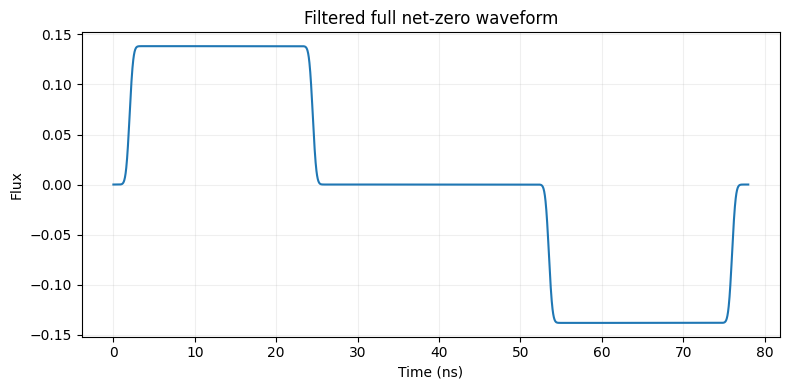

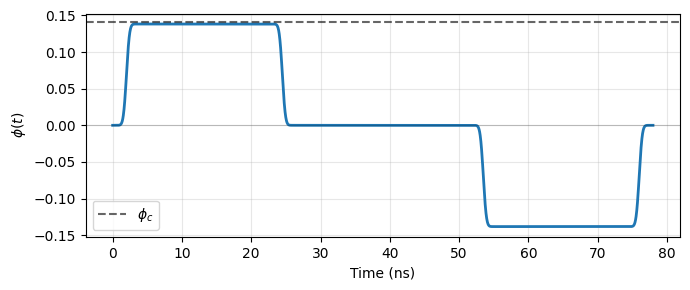

In [ ]:
# run the final simulation (without template plot inside)
final_out = run_full_nz(phi_best_3d, t_hold_half_best_3d, t_idle_best, make_plot=True)

# generate pulse figure separately
t_wf, phi_wf, phi_func_wf, T_total = make_filtered_nz_waveform(
    0.0, phi_best_3d, t_hold_half_best_3d, t_idle_best)

# reconstruct the rectangular template at the same time axis
from scipy.interpolate import interp1d
dt_rect = 0.02
t_rect = np.arange(0, T_total + dt_rect, dt_rect)
t_hold_half = t_hold_half_best_3d
t_r = 0.0  # no rise time in the rectangular template
phi_rect = np.zeros_like(t_rect)
for k, t in enumerate(t_rect):
    if t_r <= t < t_r + t_hold_half:
        phi_rect[k] = phi_best_3d
    elif t_r + t_hold_half + t_idle_best <= t < t_r + 2*t_hold_half + t_idle_best:
        phi_rect[k] = -phi_best_3d

plt.figure(figsize=(7, 3))
plt.plot(t_wf, phi_wf, lw=2, color='C0')
plt.axhline(-phi_cphase, color='k', ls='--', alpha=0.6, label=r'$\phi_c$')
plt.axhline(0, color='k', alpha=0.2, lw=0.8)
plt.xlabel('Time (ns)')
plt.ylabel(r'$\phi(t)$')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
#plt.savefig('fig_gaussian_pulse.png', dpi=150)
plt.show()

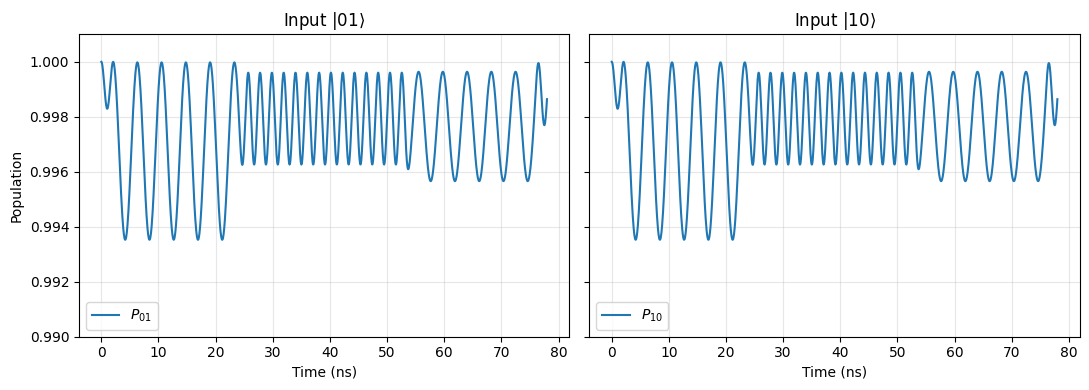

In [ ]:
#rebuild tlist and H_t from the optimised parameters
t_wf, phi_wf, phi_func_wf, T_total = make_filtered_nz_waveform(
    0.0, phi_best_3d, t_hold_half_best_3d, t_idle_best)

tlist = np.linspace(0, T_total, n_t)

def _w1(t, args=None):
    return 2*np.pi * float(w1_interp(abs(float(phi_func_wf(t)))))

def _a1(t, args=None):
    return 2*np.pi * 0.5 * float(a1_interp(abs(float(phi_func_wf(t)))))

H_t = [H2 + Hint, [n1, _w1], [kerr1, _a1]]

#exchange oscs
dims = [[n, n], [1, 1]]

psi01_0 = qt.Qobj(ket01_np.ravel(), dims=dims)
psi10_0 = qt.Qobj(ket10_np.ravel(), dims=dims)

result01 = qt.sesolve(H_t, psi01_0, tlist, options=solve_opts)
result10 = qt.sesolve(H_t, psi10_0, tlist, options=solve_opts)

P01_from01 = [float(abs(psi01_0.dag() * s)**2) for s in result01.states]
P10_from01 = [float(abs(psi10_0.dag() * s)**2) for s in result01.states]
P01_from10 = [float(abs(psi01_0.dag() * s)**2) for s in result10.states]
P10_from10 = [float(abs(psi10_0.dag() * s)**2) for s in result10.states]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].plot(tlist, P01_from01, label=r'$P_{01}$')
axes[0].set_title(r'Input $|01\rangle$')
axes[0].set_xlabel('Time (ns)')
axes[0].set_ylabel('Population')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(tlist, P10_from10, label=r'$P_{10}$')
axes[1].set_title(r'Input $|10\rangle$')
axes[1].set_xlabel('Time (ns)')
axes[1].legend(); axes[1].grid(alpha=0.3)

# zoom
for ax in axes:
    ax.set_ylim(0.990, 1.001)

plt.tight_layout()
#plt.savefig('fig_gaussian_exchange.png', dpi=150)
plt.show()

In [ ]:
#exchange oscillations


U_CZ_gauss = U_CZ

#off-diagonal exchange entries
ε_01_10 = float(np.abs(U_CZ_gauss[2, 1])**2)
ε_10_01 = float(np.abs(U_CZ_gauss[1, 2])**2)
print(f"Final |01>→|10> transfer: {ε_01_10*100:.4f}%")
print(f"Final |10>→|01> transfer: {ε_10_01*100:.4f}%")

#gate point detuning from U_CZ diagonal phases
#direct estimate from parameters
phi_final = phi_best_3d  # from Cell 1 output — update if different
w1_gate = float(w1_interp(abs(phi_final)))
delta_MHz = (w1_gate - w2) * 1000.0
g_MHz = g_val * 1000.0
print(f"\n|01>-|10> detuning at gate point: Δ = {delta_MHz:.1f} MHz")
print(f"(g/Δ)² = {(g_MHz/delta_MHz)**2*100:.3f}%, oscillation amplitude per lobe")
print(f"\nComparison:")
print(f"  Unipolar:  0.1754% transfer, Δ = 222 MHz, T ≈ 44 ns")
print(f"  Bipolar:   0.0130% transfer, Δ = 205 MHz, T ≈ 90 ns")
print(f"  Gaussian:  {ε_01_10*100:.4f}% transfer, Δ = {delta_MHz:.0f} MHz, T ≈ 59 ns")


Final |01>→|10> transfer: 0.1359%
Final |10>→|01> transfer: 0.1359%

|01>-|10> detuning at gate point: Δ = 234.8 MHz
(g/Δ)² = 0.181%, oscillation amplitude per lobe

Comparison:
  Unipolar:  0.1754% transfer, Δ = 222 MHz, T ≈ 44 ns
  Bipolar:   0.0130% transfer, Δ = 205 MHz, T ≈ 90 ns
  Gaussian:  0.1359% transfer, Δ = 235 MHz, T ≈ 59 ns


In [ ]:

#U_CZ, U_can, phases

#raw computational block from the full simulation
U_CZ = final_out["U_CZ"]

# project to nearest unitary before canonicalization
U_CZ_unitary = closest_unitary(U_CZ)
U_can = canonicalize_cz(U_CZ_unitary)

print("|U_CZ|^2:")
print(np.round(np.abs(U_CZ)**2, 4))

print("\nDiag phases of U_CZ (deg):")
print(np.round(np.degrees(np.angle(np.diag(U_CZ))), 3))

print("\n|U_can|^2:")
print(np.round(np.abs(U_can)**2, 4))

print("\nDiag phases of U_can (deg):")
print(np.round(np.degrees(np.angle(np.diag(U_can))), 3))



#realistic H on q2 (standard + DRAG) and CNOT truth tables

dim1 = 3
T_pulse_1q = 16.0
print("\npulse duration:", T_pulse_1q, "ns")
n_steps_1q = 500
detuning_1q = 0.001 * 2*np.pi
phi_drive = np.pi/2

alpha_q2_rad = 2*np.pi * float(alpha2)
print(f"q2 anharmonicity = {alpha_q2_rad/(2*np.pi)*1000:.1f} MHz")

a_1q = qt.destroy(dim1)
adag_1q = a_1q.dag()

H_drift_1q = (alpha_q2_rad / 2.0) * adag_1q * adag_1q * a_1q * a_1q + detuning_1q * adag_1q * a_1q


def hann_shape(t, T):
    if (t < 0) or (t > T):
        return 0.0
    return 0.5 * (1.0 - np.cos(2.0 * np.pi * t / T))

def deriv_hann(t, T):
    if (t < 0) or (t > T):
        return 0.0
    return 0.5 * (2.0 * np.pi / T) * np.sin(2.0 * np.pi * t / T)



def make_coeffs_1q(amp, lambda_val):
    def coeff_plus(t, args=None):
        if t > T_pulse_1q:
            return 0.0
        Ox = amp * hann_shape(t, T_pulse_1q)
        ds_dt = deriv_hann(t, T_pulse_1q)
        Oy = amp * lambda_val * ds_dt / alpha_q2_rad # divide by alpha
        envelope = -0.5 * (Ox - 1j * Oy)
        return envelope * np.exp(1j * phi_drive)

    def coeff_minus(t, args=None):
        return np.conjugate(coeff_plus(t, args)) #Hermitian: a_dagger coeff = conj of a coeff

    return coeff_plus, coeff_minus

H_ideal = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)

def gate_overlap_2x2(U, Uideal):
    phi_opt = np.angle(np.trace(Uideal.conj().T @ U))
    U_phased = U * np.exp(-1j * phi_opt)
    return float(np.abs(np.trace(Uideal.conj().T @ U_phased))**2 / 4.0)

def best_hadamard_from_U2(U2):
    gamma_grid = np.linspace(-np.pi, np.pi, 181)
    best = None

    for gamma_pre in gamma_grid:
        Rz_pre = np.array([[np.exp(-1j*gamma_pre/2), 0],
                           [0, np.exp(1j*gamma_pre/2)]], dtype=complex)
        U_pre = U2 @ Rz_pre

        for gamma_post in gamma_grid:
            Rz_post = np.array([[np.exp(-1j*gamma_post/2), 0],
                                [0, np.exp(1j*gamma_post/2)]], dtype=complex)

            H_eff = Rz_post @ U_pre
            fid = gate_overlap_2x2(H_eff, H_ideal)

            if not np.isfinite(fid):
                continue

            if (best is None) or (fid > best[0]):
                best = (fid, gamma_pre, gamma_post, H_eff)

    return best

def get_1q_unitary_from_pulse(amp, lambda_val):
    cp, cm = make_coeffs_1q(amp, lambda_val)
    H_1q = [H_drift_1q, [adag_1q, cp], [a_1q, cm]]

    U = qt.propagator(
        H_1q,
        T_pulse_1q,
        c_ops=[],
        args={},
        options={"rtol": 1e-6, "atol": 1e-8}
    )
    return U.full()

def get_hadamard_score(amp, lambda_val):
    U3 = get_1q_unitary_from_pulse(amp, lambda_val)
    U2 = U3[:2, :2]

    #project the computational block to the nearest unitary
    U2_unitary = closest_unitary(U2)

    out = best_hadamard_from_U2(U2_unitary)
    if out is None:
        return -np.inf, 0.0, 0.0, 0.0, U3, U2_unitary, np.eye(2, dtype=complex)

    fidH, gamma_pre_best, gamma_post_best, H_eff = out

    #leakage from computational columns of the original 3x3 pulse unitary
    leak0 = 1.0 - np.sum(np.abs(U3[:2, 0])**2)
    leak1 = 1.0 - np.sum(np.abs(U3[:2, 1])**2)
    leak_penalty = 0.5 * (max(0.0, leak0) + max(0.0, leak1))

    score = fidH - 5.0 * leak_penalty
    return score, float(fidH), gamma_pre_best, gamma_post_best, U3, U2_unitary, H_eff

def optimize_amp_for_lambda(lambda_val):
    res = minimize_scalar(
        lambda x: -get_hadamard_score(x, lambda_val)[0],
        bounds=(0.01, 1.5),
        method="bounded"
    )

    amp_best = float(res.x)
    score_best, fidH_best, gamma_pre_best, gamma_post_best, U3_best, U2_best, H_eff_best = get_hadamard_score(amp_best, lambda_val)
    return amp_best, score_best, fidH_best, gamma_pre_best, gamma_post_best, U3_best, U2_best, H_eff_best


#narrower lambda range
lambdas_1q = np.linspace(-0.5, 1.0, 61)

scores_1q = []
fidsH_1q = []
amps_1q = []
gammas_pre_1q = []
gammas_post_1q = []
U3_list = []
U2_list = []
Heff_list = []

for lam in lambdas_1q:
    aopt, sopt, fHopt, gpre, gpost, U3opt, U2opt, Heffopt = optimize_amp_for_lambda(lam)
    amps_1q.append(aopt)
    scores_1q.append(sopt)
    fidsH_1q.append(fHopt)
    gammas_pre_1q.append(gpre)
    gammas_post_1q.append(gpost)
    U3_list.append(U3opt)
    U2_list.append(U2opt)
    Heff_list.append(Heffopt)

#choose best by fidelity
best_idx = int(np.argmax(fidsH_1q))
best_lambda_1q = float(lambdas_1q[best_idx])
best_fid_1q = float(fidsH_1q[best_idx])

std_idx = int(np.argmin(np.abs(lambdas_1q - 0.0)))
std_fid_1q = float(fidsH_1q[std_idx])

print(f"Standard (lambda=0): fid={std_fid_1q:.6f}")
print(f"Optimal DRAG (lambda={best_lambda_1q:.3f}): fid={best_fid_1q:.6f}")

H_std_eff = Heff_list[std_idx]
H_drag_eff = Heff_list[best_idx]

print("\n|H_std|^2:")
print(np.round(np.abs(H_std_eff)**2, 4))

print("\n|H_drag|^2:")
print(np.round(np.abs(H_drag_eff)**2, 4))

I2 = np.eye(2, dtype=complex)
U_CNOT_from_stdH = np.kron(I2, H_std_eff) @ U_can @ np.kron(I2, H_std_eff)
U_CNOT_from_dragH = np.kron(I2, H_drag_eff) @ U_can @ np.kron(I2, H_drag_eff)

def print_truth_table(U, title):
    print(f"\nTruth table ({title})")
    labels = ["00", "01", "10", "11"]
    for j in range(4):
        probs = np.abs(U[:, j])**2
        print(
            f"in |{labels[j]}> -> "
            f"P(00)={probs[0]:.4f}, "
            f"P(01)={probs[1]:.4f}, "
            f"P(10)={probs[2]:.4f}, "
            f"P(11)={probs[3]:.4f}"
        )

print_truth_table(U_CNOT_from_stdH, "standard pulse H")
print_truth_table(U_CNOT_from_dragH, "DRAG pulse H")


|U_CZ|^2:
[[1.     0.     0.     0.    ]
 [0.     0.9986 0.0014 0.    ]
 [0.     0.0014 0.9986 0.    ]
 [0.     0.     0.     0.9993]]

Diag phases of U_CZ (deg):
[   0.     107.653 -166.618  120.796]

|U_can|^2:
[[1.     0.     0.     0.    ]
 [0.     0.9986 0.0014 0.    ]
 [0.     0.0014 0.9986 0.    ]
 [0.     0.     0.     1.    ]]

Diag phases of U_can (deg):
[  0.     -0.     -0.    179.761]

pulse duration: 16.0 ns
q2 anharmonicity = -223.8 MHz
Standard (lambda=0): fid=0.999929
Optimal DRAG (lambda=0.525): fid=1.000000

|H_std|^2:
[[0.498 0.502]
 [0.502 0.498]]

|H_drag|^2:
[[0.4999 0.5001]
 [0.5001 0.4999]]

Truth table (standard pulse H)
in |00> -> P(00)=0.9992, P(01)=0.0001, P(10)=0.0003, P(11)=0.0003
in |01> -> P(00)=0.0001, P(01)=0.9992, P(10)=0.0003, P(11)=0.0003
in |10> -> P(00)=0.0003, P(01)=0.0003, P(10)=0.0002, P(11)=0.9991
in |11> -> P(00)=0.0003, P(01)=0.0003, P(10)=0.9991, P(11)=0.0002

Truth table (DRAG pulse H)
in |00> -> P(00)=0.9993, P(01)=0.0000, P(10)=0.0003, 

In [ ]:
def avg_truth_success(U):
    targets = [0, 1, 3, 2]
    return float(np.mean([np.abs(U[targets[j], j])**2 for j in range(4)]))

print("average truth table success:")
print("Standard pulse H:", avg_truth_success(U_CNOT_from_stdH))
print("DRAG pulse H    :", avg_truth_success(U_CNOT_from_dragH))

average truth table success:
Standard pulse H: 0.9991521252206566
DRAG pulse H    : 0.9993189958990922


In [ ]:
#average gate fidelity
def avg_gate_fidelity(U_actual, U_ideal):
    d = U_ideal.shape[0]
    return (abs(np.trace(U_ideal.conj().T @ U_actual))**2 + d) / (d * (d + 1))

U_CZ_ideal   = np.diag([1.0, 1.0, 1.0, -1.0]).astype(complex)
U_CNOT_ideal = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]], dtype=complex)

F_CZ        = avg_gate_fidelity(U_can, U_CZ_ideal)
F_CNOT_std  = avg_gate_fidelity(U_CNOT_from_stdH,  U_CNOT_ideal)
F_CNOT_drag = avg_gate_fidelity(U_CNOT_from_dragH, U_CNOT_ideal)



print(f"F_avg(CZ,   after virtual-Z) = {F_CZ:.6f}  (infidelity = {(1-F_CZ)*100:.4f}%)")
print(f"F_avg(CNOT, standard H)      = {F_CNOT_std:.6f}  (infidelity = {(1-F_CNOT_std)*100:.4f}%)")
print(f"F_avg(CNOT, DRAG H)          = {F_CNOT_drag:.6f}  (infidelity = {(1-F_CNOT_drag)*100:.4f}%)")

print(f"\nTruth-table success (standard H): {avg_truth_success(U_CNOT_from_stdH):.6f}")
print(f"Truth-table success (DRAG H):     {avg_truth_success(U_CNOT_from_dragH):.6f}")

print(f"The dominant error is the CZ gate itself (0.0051 off-diagonal = {ε_01_10*100:.3f}% exchange).")


F_avg(CZ,   after virtual-Z) = 0.999454  (infidelity = 0.0546%)
F_avg(CNOT, standard H)      = 0.999268  (infidelity = 0.0732%)
F_avg(CNOT, DRAG H)          = 0.999454  (infidelity = 0.0546%)

Truth-table success (standard H): 0.999152
Truth-table success (DRAG H):     0.999319
The dominant error is the CZ gate itself (0.0051 off-diagonal = 0.136% exchange).


computing chevrons:
  row 1/81
  row 11/81
  row 21/81
  row 31/81
  row 41/81
  row 51/81
  row 61/81
  row 71/81
  row 81/81
  row 91/81
  row 101/81
  row 111/81
  row 121/81


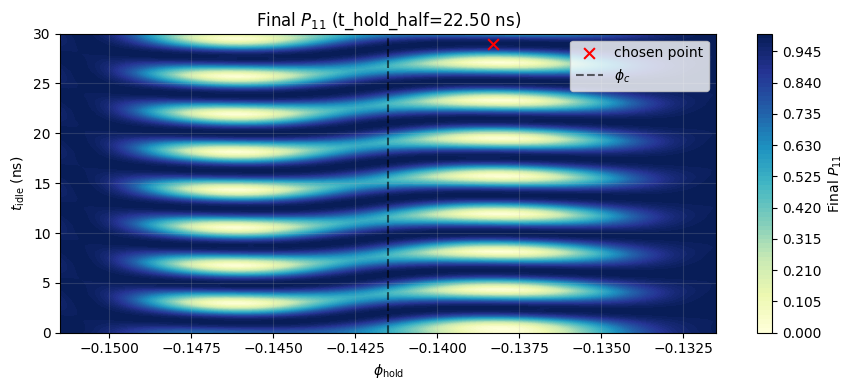

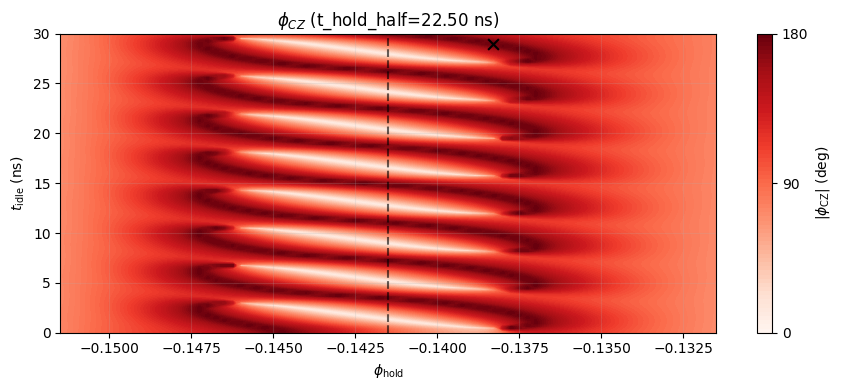

In [ ]:
from scipy.linalg import expm as la_expm

Hconst_np = (H2 + Hint).full()
n1_np     = n1.full()
kerr1_np  = kerr1.full()

def wrap_deg_signed(x):
    return (x + 180.0) % 360.0 - 180.0

def fast_chevron_point(phi, t_idle, t_hold_half_fixed, DT=0.50):
    t_wf, phi_wf, phi_func_wf, T_total = make_filtered_nz_waveform(
        0.0, phi, t_hold_half_fixed, t_idle)

    nsteps = int(np.ceil(T_total / DT))
    tcoarse = np.linspace(0.0, T_total, nsteps + 1)
    dt = tcoarse[1] - tcoarse[0]
    phi_coarse = phi_func_wf(tcoarse)

    w1_t  = 2*np.pi * np.array([float(w1_interp(p)) for p in phi_coarse])
    a1h_t = 2*np.pi * 0.5 * np.array([float(a1_interp(p)) for p in phi_coarse])

    Psi = np.column_stack([
        ket00_np.ravel(), ket01_np.ravel(),
        ket10_np.ravel(), ket11_np.ravel()
    ])

    for k in range(nsteps):
        w_mid = 0.5*(w1_t[k] + w1_t[k+1])
        a_mid = 0.5*(a1h_t[k] + a1h_t[k+1])
        Hmid  = Hconst_np + w_mid*n1_np + a_mid*kerr1_np
        U     = la_expm(-1j * Hmid * dt)
        Psi   = U @ Psi

    u00 = ket00_np.ravel().conj() @ Psi[:, 0]
    u01 = ket01_np.ravel().conj() @ Psi[:, 1]
    u10 = ket10_np.ravel().conj() @ Psi[:, 2]
    u11 = ket11_np.ravel().conj() @ Psi[:, 3]

    P11 = float(abs(u11)**2)
    phiCZ_deg = abs(wrap_deg_signed(
        np.degrees(np.angle(u11 * u00 * np.conj(u10 * u01)))))

    return P11, phiCZ_deg

# chevron: phi vs t_idle, t_hold_half fixed at optimal
phi_grid    = np.linspace(phi_cphase - 0.010, phi_cphase + 0.010, 81)
t_idle_grid = np.linspace(0.0, 30.0, 121)
th_fixed    = float(t_hold_half_best_3d)
ph_star     = float(phi_best_3d)
tb_star     = float(t_idle_best)

P11_map = np.zeros((len(t_idle_grid), len(phi_grid)))
CZ_map  = np.zeros_like(P11_map)

print("computing chevrons:")
for iy, tb in enumerate(t_idle_grid):
    for ix, ph in enumerate(phi_grid):
        P11_map[iy, ix], CZ_map[iy, ix] = fast_chevron_point(ph, tb, th_fixed)
    if iy % 10 == 0:
        print(f"  row {iy+1}/81")

X, Y = np.meshgrid(phi_grid, t_idle_grid)

plt.figure(figsize=(9, 4))
cp = plt.contourf(X, Y, P11_map, 80, cmap="YlGnBu", vmin=0, vmax=1)
cp.set_edgecolor("face")
plt.colorbar(cp, label="Final $P_{11}$")
plt.scatter([ph_star], [tb_star], s=60, c="r", marker="x", label="chosen point")
plt.axvline(phi_cphase, color="k", ls="--", alpha=0.6, label=r"$\phi_c$")
plt.title(f"Final $P_{{11}}$ (t_hold_half={th_fixed:.2f} ns)")
plt.xlabel(r"$\phi_{\rm hold}$")
plt.ylabel(r"$t_{\rm idle}$ (ns)")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
#plt.savefig("fig_gaussian_chevron_P11.png", dpi=150)
plt.show()

plt.figure(figsize=(9, 4))
cp = plt.contourf(X, Y, CZ_map, 80, cmap="Reds", vmin=0, vmax=180)
cp.set_edgecolor("face")
cbar = plt.colorbar(cp, label=r"$|\phi_{\rm CZ}|$ (deg)")
cbar.set_ticks([0, 90, 180])
plt.scatter([ph_star], [tb_star], s=60, c="k", marker="x")
plt.axvline(phi_cphase, color="k", ls="--", alpha=0.6)
plt.title(f"$\\phi_{{CZ}}$ (t_hold_half={th_fixed:.2f} ns)")
plt.xlabel(r"$\phi_{\rm hold}$")
plt.ylabel(r"$t_{\rm idle}$ (ns)")
plt.grid(alpha=0.2)
plt.tight_layout()
#plt.savefig("fig_gaussian_chevron_phase.png", dpi=150)
plt.show()